# 04 · BERT: embeddings congelados y fine-tuning

**Responsable:** María Sánchez · **Se ejecuta en Google Colab con GPU**
(*Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU T4*)

En este notebook usamos un Transformer preentrenado de tipo *encoder-only* (BERT) de dos formas:

1. **Como extractor de características (pesos congelados).** Pasamos cada resumen por BERT,
   obtenemos un vector por documento y entrenamos encima una regresión logística.
   Estos vectores también se los pasamos a Lucía F. para su red en PyTorch.
2. **Fine-tuning.** Añadimos una capa de clasificación encima de BERT y entrenamos **todo** el
   modelo con nuestras etiquetas: aquí los pesos de BERT sí cambian.

Como pide el enunciado, BERT recibe el **texto sin preprocesar** (sin quitar stopwords ni lematizar):
el modelo tiene su propio tokenizador y necesita las frases completas para entender el contexto.

## 0. Preparación

In [9]:
import os
import copy
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from transformers import AutoTokenizer, AutoModel, AutoModelForSequenceClassification
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import f1_score, accuracy_score

# Igual que en el notebook DL2 de clase
def get_best_device():
    if torch.cuda.is_available():
        return torch.device("cuda")
    print("No hay GPU: activa la GPU en Colab (Entorno de ejecución → Cambiar tipo de entorno)")
    return torch.device("cpu")

dispositivo = get_best_device()
print(dispositivo)   # tiene que salir "cuda"

# Semillas para que los resultados sean reproducibles
torch.manual_seed(42)
np.random.seed(42)

# En Colab subimos a /content/ los ficheros: proyectos_etiquetados.pkl (sale del notebook 01)
# y particion.csv (está en resultados/ del repositorio)
RUTA = "/content/"

cuda


In [10]:
# Montamos Google Drive para guardar los embeddings y compartirlos con Lucía F.
from google.colab import drive
drive.mount("/content/drive")

RUTA_DRIVE = "/content/drive/MyDrive/cordis_embeddings/"
RUTA = RUTA_DRIVE   # entradas y resultados en Drive: sobreviven a una desconexion
os.makedirs(RUTA_DRIVE, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [11]:
datos = pd.read_pickle(RUTA + "proyectos_etiquetados.pkl")
particion = pd.read_csv(RUTA + "particion.csv")
datos = datos.merge(particion, on="projectID")

# Ordenamos por projectID dentro de cada conjunto: así el orden de los embeddings
# es siempre el mismo y Lucía F. puede emparejarlos con las etiquetas sin errores
train = datos[datos["conjunto"] == "train"].sort_values("projectID").reset_index(drop=True)
val = datos[datos["conjunto"] == "val"].sort_values("projectID").reset_index(drop=True)
test = datos[datos["conjunto"] == "test"].sort_values("projectID").reset_index(drop=True)
print(len(train), len(val), len(test))   # 22386 4798 4798

22386 4798 4798


## 1. Modelo y longitud de los resúmenes

Usamos **`bert-base-uncased`**: es el BERT original que vimos en clase (12 capas, vectores de 768
dimensiones) y es lo bastante pequeño para hacer fine-tuning en la GPU gratuita de Colab.

BERT admite como máximo **512 tokens**. Un token no es una palabra: las palabras poco frecuentes se
parten en varios trozos (por ejemplo, *photovoltaic* → *photo*, *##vol*, *##taic*). Por eso medimos
la longitud con el propio tokenizador.

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (625 > 512). Running this sequence through the model will result in indexing errors


Mediana de tokens: 366
Resúmenes de más de 512 tokens: 0.1 %


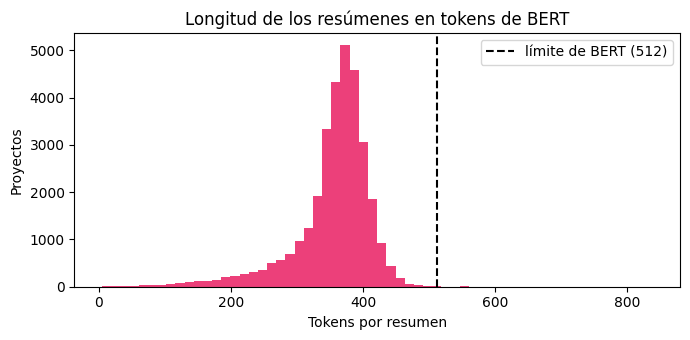

In [12]:
MODELO = "bert-base-uncased"
tokenizador = AutoTokenizer.from_pretrained(MODELO)

# Número de tokens de cada resumen (sin truncar)
n_tokens = [len(t) for t in tokenizador(list(datos["summary"]), truncation=False)["input_ids"]]
n_tokens = np.array(n_tokens)

print(f"Mediana de tokens: {np.median(n_tokens):.0f}")
print(f"Resúmenes de más de 512 tokens: {100 * (n_tokens > 512).mean():.1f} %")

plt.figure(figsize=(7, 3.5))
plt.hist(n_tokens, bins=60, color="#ec407a")
plt.axvline(512, color="black", linestyle="--", label="límite de BERT (512)")
plt.xlabel("Tokens por resumen")
plt.ylabel("Proyectos")
plt.legend()
plt.title("Longitud de los resúmenes en tokens de BERT")
plt.tight_layout()
plt.savefig(RUTA + "bert_longitud_tokens.png", dpi=120)
plt.show()

**Decisión: truncar a 512 tokens.** Nos quedamos con el principio de cada resumen, que es donde
normalmente se explica de qué trata el proyecto. Como solo afecta a un porcentaje pequeño de
resúmenes (ver arriba), y en ellos solo perdemos el final, no merece la pena una estrategia más
compleja (como partir el texto en trozos y promediar).

## 2. Embeddings congelados

BERT devuelve **un vector por token**. Para tener un único vector por documento probamos dos
opciones (*pooling*):

- **[CLS]**: el vector del token especial que BERT pone al principio de cada texto.
- **Media (mean pooling)**: la media de los vectores de todos los tokens reales
  (sin contar el relleno o *padding*, que se ignora gracias a la `attention_mask`).

Las dos se calculan en la misma pasada y elegimos con validación cuál funciona mejor.
Los pesos de BERT no se modifican: `model.eval()` y `torch.no_grad()`.

In [13]:
bert = AutoModel.from_pretrained(MODELO).to(dispositivo)
bert.eval()   # modo evaluación: sin dropout

def extraer_embeddings(textos, tam_lote=64):
    """Devuelve dos matrices (n_textos x 768): pooling [CLS] y pooling por media."""
    cls_todos, media_todos = [], []
    for i in range(0, len(textos), tam_lote):
        lote = tokenizador(textos[i:i + tam_lote], truncation=True, max_length=512,
                           padding=True, return_tensors="pt").to(dispositivo)
        with torch.no_grad(), torch.autocast(device_type="cuda", dtype=torch.float16):
            salida = bert(**lote).last_hidden_state          # (lote, tokens, 768)

        salida = salida.float()
        cls_todos.append(salida[:, 0, :].cpu().numpy())      # primer token = [CLS]

        mascara = lote["attention_mask"].unsqueeze(-1).float()   # 1 = token real, 0 = padding
        media = (salida * mascara).sum(dim=1) / mascara.sum(dim=1)
        media_todos.append(media.cpu().numpy())
    return np.vstack(cls_todos), np.vstack(media_todos)

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [14]:
# Tarda unos minutos con GPU (aprox. 32.000 resúmenes)
emb = {}
for nombre, df in [("train", train), ("val", val), ("test", test)]:
    inicio = time.time()
    emb[("cls", nombre)], emb[("media", nombre)] = extraer_embeddings(list(df["summary"]))
    print(f"{nombre}: {time.time() - inicio:.0f} s")

# Guardamos en Drive (para Lucía F.) los vectores y el orden de los proyectos
for (pooling, nombre), matriz in emb.items():
    np.save(RUTA_DRIVE + f"emb_{pooling}_{nombre}.npy", matriz)
for nombre, df in [("train", train), ("val", val), ("test", test)]:
    df[["projectID"]].to_csv(RUTA_DRIVE + f"orden_{nombre}.csv", index=False)
print("Guardado en", RUTA_DRIVE)

train: 186 s
val: 43 s
test: 42 s
Guardado en /content/drive/MyDrive/cordis_embeddings/


## 3. Regresión logística sobre los embeddings congelados

Escalamos los vectores (`StandardScaler`, ajustado **solo con train**) y entrenamos una regresión
logística. Elegimos el pooling y la regularización `C` con el **macro-F1 en validación**.

In [15]:
def guardar_predicciones(df, y_pred, modelo, nivel, conjunto):
    pd.DataFrame({"projectID": df["projectID"], "y_true": df[nivel], "y_pred": y_pred}) \
      .to_csv(RUTA + f"{modelo}_{nivel}_{conjunto}.csv", index=False)

busqueda = []
for pooling in ["cls", "media"]:
    for C in [0.01, 0.1, 1]:
        clf = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=2000))
        clf.fit(emb[(pooling, "train")], train["nivel2"])
        pred = clf.predict(emb[(pooling, "val")])
        busqueda.append({"pooling": pooling, "C": C,
                         "val accuracy": accuracy_score(val["nivel2"], pred),
                         "val macro-F1": f1_score(val["nivel2"], pred, average="macro")})
        print(busqueda[-1])

busqueda = pd.DataFrame(busqueda).round(3)
busqueda.to_csv(RUTA + "bert_logreg_busqueda.csv", index=False)
busqueda.sort_values("val macro-F1", ascending=False)

{'pooling': 'cls', 'C': 0.01, 'val accuracy': 0.4337223843268028, 'val macro-F1': 0.2824793099068402}
{'pooling': 'cls', 'C': 0.1, 'val accuracy': 0.3949562317632347, 'val macro-F1': 0.2650211035106173}
{'pooling': 'cls', 'C': 1, 'val accuracy': 0.3689037098791163, 'val macro-F1': 0.2475271951392214}
{'pooling': 'media', 'C': 0.01, 'val accuracy': 0.460817007086286, 'val macro-F1': 0.30186135585464235}
{'pooling': 'media', 'C': 0.1, 'val accuracy': 0.4414339308045019, 'val macro-F1': 0.2966670982710693}
{'pooling': 'media', 'C': 1, 'val accuracy': 0.4114214255939975, 'val macro-F1': 0.27259090131623287}


,pooling,C,val accuracy,val macro-F1
3,media,0.01,0.461,0.302
4,media,0.10,0.441,0.297
0,cls,0.01,0.434,0.282
5,media,1.00,0.411,0.273
1,cls,0.10,0.395,0.265
2,cls,1.00,0.369,0.248


Configuración elegida: media 0.01


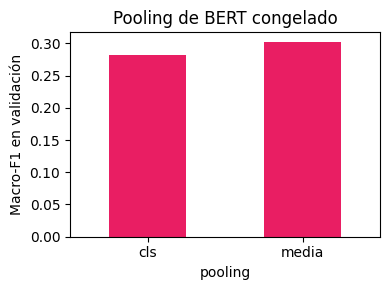

In [16]:
mejor = busqueda.loc[busqueda["val macro-F1"].idxmax()]
POOLING, C = mejor["pooling"], mejor["C"]
print("Configuración elegida:", POOLING, C)

# Comparación de los dos tipos de pooling (mejor C de cada uno)
busqueda.groupby("pooling")["val macro-F1"].max().plot(kind="bar", color="#e91e63", figsize=(4, 3))
plt.ylabel("Macro-F1 en validación")
plt.title("Pooling de BERT congelado")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(RUTA + "bert_pooling.png", dpi=120)
plt.show()

In [17]:
# Con la configuración ya elegida: entrenamos y predecimos val y test (test solo esta vez)
for nivel in ["nivel2", "nivel1"]:
    clf = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=2000))
    clf.fit(emb[(POOLING, "train")], train[nivel])
    for nombre, df in [("val", val), ("test", test)]:
        guardar_predicciones(df, clf.predict(emb[(POOLING, nombre)]), "bert_logreg", nivel, nombre)
print("Predicciones guardadas")

Predicciones guardadas


## 4. Fine-tuning

Ahora BERT se **entrena** con nuestras etiquetas. `AutoModelForSequenceClassification` añade
encima de BERT una capa lineal (768 → número de clases) que usa el vector [CLS], y entrenamos
todos los pesos con entropía cruzada y el optimizador AdamW, como en los notebooks de PyTorch de clase.

- **Learning rate pequeño** (del orden de 2e-5): BERT ya sabe mucho del lenguaje y solo queremos
  ajustarlo, no destruir lo que sabe.
- **Early stopping**: tras cada época medimos el macro-F1 en validación y nos quedamos con la mejor
  época. Si empeora, paramos.
- Elegimos el learning rate entre dos valores con validación.

El bucle de entrenamiento es el mismo que en el notebook DL2 de clase (`zero_grad`, `backward`,
`step`), con dos añadidos para que quepa en el tiempo de Colab:
- **`torch.autocast(..., float16)`**: hace los cálculos en media precisión (16 bits en lugar de 32).
  En la GPU es casi el doble de rápido y apenas cambia el resultado.
- **`GradScaler`**: con 16 bits, los gradientes muy pequeños pueden redondearse a cero; el escalador
  multiplica la pérdida antes de `backward()` y deshace el cambio antes de actualizar los pesos.

Cada época tarda bastante en la GPU de Colab, por eso probamos pocas configuraciones.

In [18]:
class DatasetTextos(torch.utils.data.Dataset):
    """Tokeniza los textos una vez y devuelve un ejemplo (tokens + etiqueta) cada vez."""
    def __init__(self, textos, etiquetas):
        self.codif = tokenizador(list(textos), truncation=True, max_length=512, padding="max_length")
        self.etiquetas = list(etiquetas)
    def __len__(self):
        return len(self.etiquetas)
    def __getitem__(self, i):
        ejemplo = {k: torch.tensor(v[i]) for k, v in self.codif.items()}
        ejemplo["labels"] = torch.tensor(self.etiquetas[i])
        return ejemplo

def predecir(modelo, cargador):
    """Devuelve las clases predichas (índices) y la pérdida media."""
    modelo.eval()
    preds, perdida = [], 0
    with torch.no_grad():
        for lote in cargador:
            lote = {k: v.to(dispositivo) for k, v in lote.items()}
            with torch.autocast(device_type="cuda", dtype=torch.float16):
                salida = modelo(**lote)
            perdida += salida.loss.item()
            preds.append(salida.logits.argmax(dim=1).cpu().numpy())
    return np.concatenate(preds), perdida / len(cargador)

In [19]:
def fine_tuning(nivel, lr, max_epocas=3, tam_lote=16):
    clases = sorted(train[nivel].unique())
    a_indice = {c: i for i, c in enumerate(clases)}

    cargadores = {}
    for nombre, df in [("train", train), ("val", val), ("test", test)]:
        ds = DatasetTextos(df["summary"], df[nivel].map(a_indice))
        cargadores[nombre] = torch.utils.data.DataLoader(ds, batch_size=tam_lote, shuffle=(nombre == "train"))

    modelo = AutoModelForSequenceClassification.from_pretrained(MODELO, num_labels=len(clases)).to(dispositivo)
    optimizador = torch.optim.AdamW(modelo.parameters(), lr=lr, weight_decay=0.01)
    escalador = torch.cuda.amp.GradScaler()   # para entrenar en float16 sin problemas numéricos

    historial, mejor_f1 = [], -1
    for epoca in range(1, max_epocas + 1):
        modelo.train()
        perdida_train, inicio = 0, time.time()
        for lote in cargadores["train"]:
            lote = {k: v.to(dispositivo) for k, v in lote.items()}
            optimizador.zero_grad()
            with torch.autocast(device_type="cuda", dtype=torch.float16):
                perdida = modelo(**lote).loss
            escalador.scale(perdida).backward()
            escalador.step(optimizador)
            escalador.update()
            perdida_train += perdida.item()

        pred_val, perdida_val = predecir(modelo, cargadores["val"])
        f1_val = f1_score(val[nivel].map(a_indice), pred_val, average="macro")
        historial.append({"época": epoca, "pérdida train": perdida_train / len(cargadores["train"]),
                          "pérdida val": perdida_val, "val macro-F1": f1_val})
        print(f"lr={lr} época {epoca}: {historial[-1]}  ({time.time() - inicio:.0f} s)")

        if f1_val > mejor_f1:                    # guardamos la mejor época (como en DL2)
            mejor_f1 = f1_val
            mejor_estado = copy.deepcopy(modelo.state_dict())
        else:                                    # early stopping (paciencia = 1 época)
            print("El macro-F1 en validación no mejora: paramos")
            break

    modelo.load_state_dict(mejor_estado)
    return modelo, cargadores, clases, pd.DataFrame(historial)

In [20]:
# Búsqueda del learning rate (nivel 2). Cada configuración tarda bastante (unos 10 min por época):
# si Colab se desconecta, se puede ejecutar cada lr en una sesión distinta.
# Guardamos las predicciones de cada configuración para no tener que reentrenar la elegida;
# las de test NO se miran para decidir: la elección se hace solo con validación.
resultados_ft, predicciones_ft = {}, {}
for lr in [2e-5, 3e-5]:
    modelo, cargadores, clases, historial = fine_tuning("nivel2", lr)
    resultados_ft[lr] = historial
    historial.to_csv(RUTA + f"bert_finetune_historial_lr{lr}.csv", index=False)
    predicciones_ft[lr] = {nombre: [clases[i] for i in predecir(modelo, cargadores[nombre])[0]]
                           for nombre in ["val", "test"]}
    del modelo
    torch.cuda.empty_cache()

for lr, h in resultados_ft.items():
    print(f"lr={lr}: mejor val macro-F1 = {h['val macro-F1'].max():.3f}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/tmp/ipykernel_2251/20

lr=2e-05 época 1: {'época': 1, 'pérdida train': 2.109742924826486, 'pérdida val': 1.6721831858158112, 'val macro-F1': 0.3059942776937996}  (669 s)
lr=2e-05 época 2: {'época': 2, 'pérdida train': 1.508729019165039, 'pérdida val': 1.5137250717480977, 'val macro-F1': 0.3677752157933378}  (666 s)
lr=2e-05 época 3: {'época': 3, 'pérdida train': 1.2172952944891793, 'pérdida val': 1.481939445734024, 'val macro-F1': 0.39530743165663834}  (666 s)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/tmp/ipykernel_2251/20

lr=3e-05 época 1: {'época': 1, 'pérdida train': 2.021695728302002, 'pérdida val': 1.6146175857385, 'val macro-F1': 0.3189135292057464}  (669 s)
lr=3e-05 época 2: {'época': 2, 'pérdida train': 1.4731607682364327, 'pérdida val': 1.508012992143631, 'val macro-F1': 0.36801386364852057}  (666 s)
lr=3e-05 época 3: {'época': 3, 'pérdida train': 1.171083790234157, 'pérdida val': 1.480718236764272, 'val macro-F1': 0.42039698698359557}  (668 s)
lr=2e-05: mejor val macro-F1 = 0.395
lr=3e-05: mejor val macro-F1 = 0.420


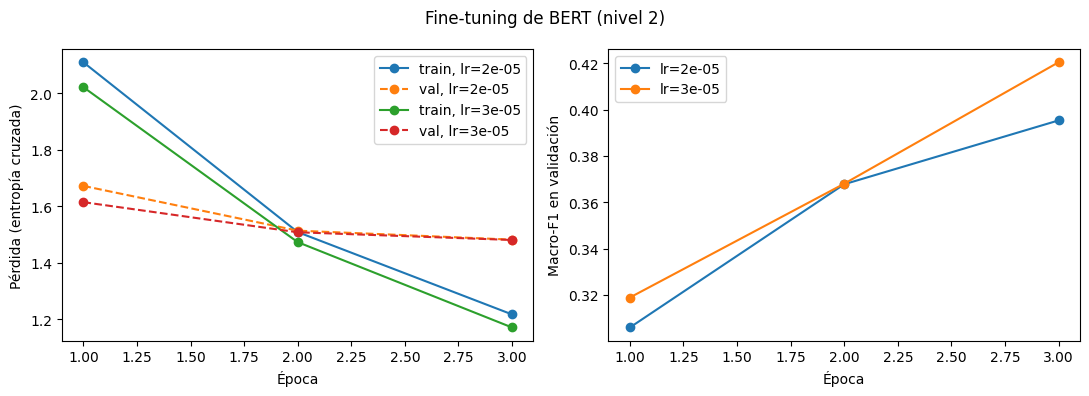

In [21]:
# Curvas de aprendizaje
fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
for lr, h in resultados_ft.items():
    ejes[0].plot(h["época"], h["pérdida train"], marker="o", label=f"train, lr={lr}")
    ejes[0].plot(h["época"], h["pérdida val"], marker="o", linestyle="--", label=f"val, lr={lr}")
    ejes[1].plot(h["época"], h["val macro-F1"], marker="o", label=f"lr={lr}")
ejes[0].set_xlabel("Época"); ejes[0].set_ylabel("Pérdida (entropía cruzada)"); ejes[0].legend()
ejes[1].set_xlabel("Época"); ejes[1].set_ylabel("Macro-F1 en validación"); ejes[1].legend()
fig.suptitle("Fine-tuning de BERT (nivel 2)")
plt.tight_layout()
plt.savefig(RUTA + "bert_finetune_curvas.png", dpi=120)
plt.show()

In [22]:
# Elegimos el learning rate con validación y guardamos sus predicciones de nivel 2
LR = max(resultados_ft, key=lambda lr: resultados_ft[lr]["val macro-F1"].max())
print("Learning rate elegido:", LR)
for nombre, df in [("val", val), ("test", test)]:
    guardar_predicciones(df, predicciones_ft[LR][nombre], "bert_finetune", "nivel2", nombre)

# Nivel 1: repetimos con la configuración elegida
modelo, cargadores, clases, historial = fine_tuning("nivel1", LR)
historial.to_csv(RUTA + "bert_finetune_historial_nivel1.csv", index=False)
for nombre, df in [("val", val), ("test", test)]:
    pred, _ = predecir(modelo, cargadores[nombre])
    guardar_predicciones(df, [clases[i] for i in pred], "bert_finetune", "nivel1", nombre)
print("Predicciones guardadas")

Learning rate elegido: 3e-05


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/tmp/ipykernel_2251/20

lr=3e-05 época 1: {'época': 1, 'pérdida train': 0.893524637903486, 'pérdida val': 0.7985252598921458, 'val macro-F1': 0.6301387609322536}  (668 s)
lr=3e-05 época 2: {'época': 2, 'pérdida train': 0.6940549577985491, 'pérdida val': 0.7559947049617768, 'val macro-F1': 0.6446015767039194}  (666 s)
lr=3e-05 época 3: {'época': 3, 'pérdida train': 0.5544504271234785, 'pérdida val': 0.8141930729150773, 'val macro-F1': 0.6488977454155396}  (667 s)
Predicciones guardadas


In [23]:
import os, glob, shutil

os.makedirs("/content/entrega/resultados", exist_ok=True)
os.makedirs("/content/entrega/figuras", exist_ok=True)

for f in glob.glob(RUTA + "bert_*.csv"):
    shutil.copy(f, "/content/entrega/resultados/")
for f in glob.glob(RUTA + "bert_*.png"):
    shutil.copy(f, "/content/entrega/figuras/")

print("resultados:", sorted(os.listdir("/content/entrega/resultados")))
print("figuras:   ", sorted(os.listdir("/content/entrega/figuras")))

resultados: ['bert_finetune_historial_lr2e-05.csv', 'bert_finetune_historial_lr3e-05.csv', 'bert_finetune_historial_nivel1.csv', 'bert_finetune_nivel1_test.csv', 'bert_finetune_nivel1_val.csv', 'bert_finetune_nivel2_test.csv', 'bert_finetune_nivel2_val.csv', 'bert_logreg_busqueda.csv', 'bert_logreg_nivel1_test.csv', 'bert_logreg_nivel1_val.csv', 'bert_logreg_nivel2_test.csv', 'bert_logreg_nivel2_val.csv']
figuras:    ['bert_finetune_curvas.png', 'bert_longitud_tokens.png', 'bert_pooling.png']


In [24]:
!cd /content/entrega && zip -r /content/entrega_bert.zip resultados figuras
from google.colab import files
files.download("/content/entrega_bert.zip")

  adding: resultados/ (stored 0%)
  adding: resultados/bert_finetune_historial_lr2e-05.csv (deflated 31%)
  adding: resultados/bert_logreg_busqueda.csv (deflated 35%)
  adding: resultados/bert_finetune_nivel1_test.csv (deflated 90%)
  adding: resultados/bert_finetune_historial_nivel1.csv (deflated 31%)
  adding: resultados/bert_logreg_nivel2_test.csv (deflated 89%)
  adding: resultados/bert_logreg_nivel1_test.csv (deflated 90%)
  adding: resultados/bert_finetune_historial_lr3e-05.csv (deflated 31%)
  adding: resultados/bert_finetune_nivel2_test.csv (deflated 89%)
  adding: resultados/bert_finetune_nivel1_val.csv (deflated 90%)
  adding: resultados/bert_logreg_nivel2_val.csv (deflated 89%)
  adding: resultados/bert_finetune_nivel2_val.csv (deflated 89%)
  adding: resultados/bert_logreg_nivel1_val.csv (deflated 90%)
  adding: figuras/ (stored 0%)
  adding: figuras/bert_finetune_curvas.png (deflated 7%)
  adding: figuras/bert_longitud_tokens.png (deflated 16%)
  adding: figuras/bert_pooli

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 5. Antes de cerrar Colab

Descargar de `/content/` (panel de Archivos → clic derecho → Descargar) y copiar en el repositorio:
- a `resultados/`: `bert_logreg_*.csv`, `bert_finetune_*.csv`, `bert_logreg_busqueda.csv` y los historiales;
- a `figuras/`: `bert_longitud_tokens.png`, `bert_pooling.png`, `bert_finetune_curvas.png`;
- este notebook: *Archivo → Descargar → Descargar .ipynb* → `notebooks/04_bert.ipynb`.

Los embeddings (`.npy`) **no** se suben a GitHub (pesan mucho): se quedan en Drive para Lucía F.